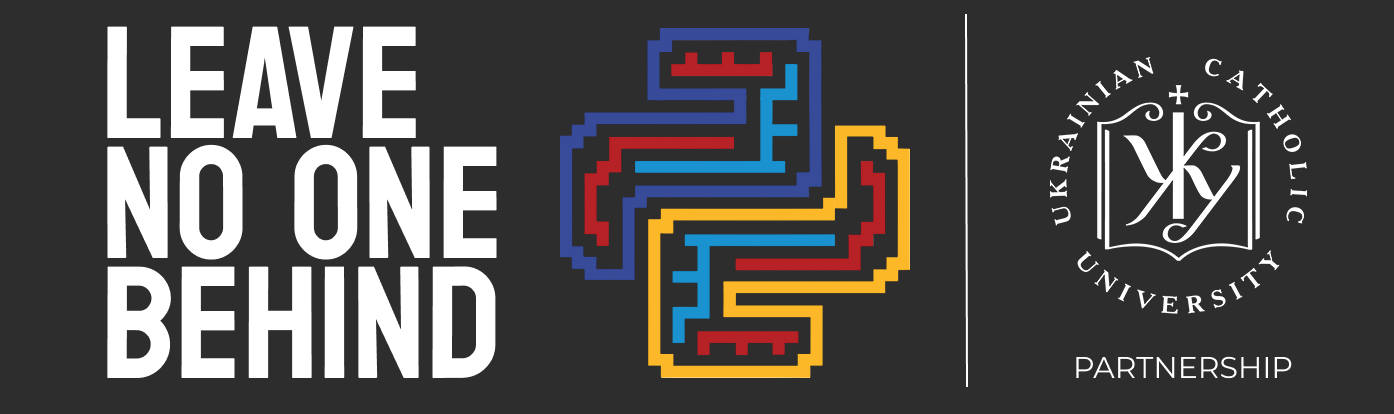

Перед Вами версія 1.0 навчальних матеріалів, що були створені командою Факультету прикладних наук Українського католицького університету в рамках освітнього проєкту ["Не залишити нікого осторонь"](https://www.facebook.com/leavenoonebehindpartnership/) 2024 року. Ми &mdash; Радомир Гусєв, Лідія Семсічко, Антон Валігурський, Максим Жук, Тетяна Захарченко &mdash; створювали його з любовʼю. Будемо вдячні, якщо наша праця буде завжди мати вказане авторство. Ліцензовано під [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/)

Чарівного Вам кодування!

# Робота з файлами

## Зміст

- [0. tl;dr - too long didn't read](#tldr)
- [1. Файлова структура та особливості на Google Colab](#files)
- [2. `os`](#os)
- [3. Відкриття файлів](#file-open)
- [4. Читання й запис](#read-write)

<a id="tldr"></a>
## 0. tl;dr - too long didn't read

Відкриття файлу:
- на читання - `with open(<шлях>, "r") as file:`
- на запис - `with open(<шлях>, "w") as file:`
- на додавання до кінця файлу - `with open(<шлях>, "a") as file:`
- читання із записом одночасно - `with open(<шлях>, "r+") as file:`

Читання. Увесь файл:

In [ ]:
with open("sample_data/README.md", "r") as file:
    print(file.read())

Перші `n` символів, наступні `k` символів:

In [ ]:
with open("sample_data/README.md", "r") as file:
    print(file.read(10))
    print(file.read(4))

Усі рядки/перший рядок:

In [ ]:
with open("sample_data/README.md", "r") as file:
    print(file.readlines())

with open("sample_data/README.md", "r") as file:
    print(file.readline())
    print(file.readline())
    print(file.readline())

Аби дізнатися поточну позицію та змінити її - `.tell()` та `.seek(<позиція>)`:

In [ ]:
with open("sample_data/README.md", "r") as file:
    print(file.tell())
    print(file.readline())
    print(file.tell())
    print(file.seek(0))
    print(file.tell())
    print(file.readline())
    print(file.tell())

Писання (перезаписує файл, якщо такий існував):

In [ ]:
filepath = "sample_data/tmp_file.txt"

In [ ]:
# запис
with open(filepath, "w") as file:
    file.write("Hello, world!")

with open(filepath, "r") as file:
    print(file.read())

In [ ]:
# додавання до кінця файлу
with open(filepath, "a") as file:
    file.write("\nand mom!")

with open(filepath, "r") as file:
    print(file.read())

In [ ]:
# перезапис існуючого файлу
with open(filepath, "w") as file:
    file.write("No,")
    # другий вже не витирає того, що раніше записали з цією змінною
    file.write(" not hello")

with open(filepath, "r") as file:
    print(file.read())

Є різні корисні функціх для роботи із файловою системою в бібліотеці `os`:
- `os.chdir(<шлях>)` - перейти в директорію;
- `os.getcwd()` - отримати поточний шлях;
- `os.mkdir(<шлях>)` - створити директорію;
- `os.walk(<шлях>)` - пройтися (проітеруватися) по всіх елементах цієї директорії, а також проітеруватися по елементах всіх піддиректорій і тд.;
- `os.path.isfile(<шлях>)` - чи є шляхом файлом;
- `os.path.exists(<шлях>)` - чи існує щось за цим шляхом;
- `os.path.dirname(<шлях>)` - отримати шлях до батьківської директорії;
- `os.path.isdir(<шлях>)` - чи є шлях директорією.

Для складніших завдань існують також бібліотеки `shutil` та `glob`.

<a id="files"></a>
## 1. Файлова структура та особливості на Google Colab

Google Colab усередині використовує операційну систему Linux - це означає, що він часто поводиться так, як прийнято на більшості операційних систем, як-от BSD (в тому числі MacOS), Linux та багато інших.

Однак якщо ви не користувалися стандартними інструментами, а тільки наданими у Windows, то деколи ця поведінка може здаватися незвичною. Погляньмо на декілька прикладів, які безпосередньо нас стосуватимуться.

Поняття директорій (папок) та файлів досить схожі до тих, що на Windows. Переглянути їхню структуру можна використавши вкладку зліва:

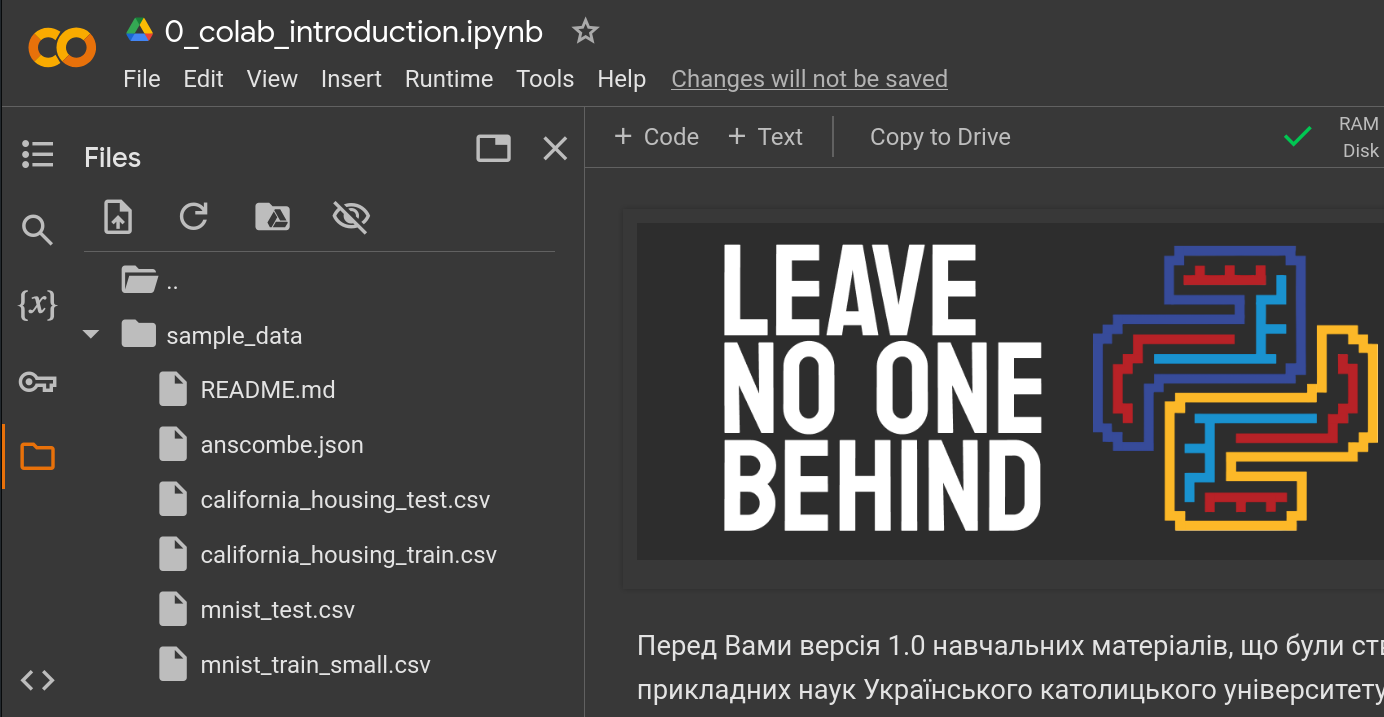

Примітка: для перегляду файлів потрібно під'єднатися до runtime (виділеної віртуальної машини від Colab, на якій виконується весь код). Якщо це не стається автоматично при відкритті вкладки, то натисніть "connect" у правому верхньому кутку вікна.

За замовчуванням Colab одразу створює директорію (папку) "sample_data" із кількома файлами.

Можемо також переглянути поточну відкриту директорію з допомогою "магічної команди" `%pwd` (pwd - print working directory):

In [1]:
%pwd

'/home/user/python/ucu-study/t7/theory'

Бачимо першу відмінність Windows: а більшості систем прийнято використовувати "/" як роздільник між директоріями, в той час як на Windows "\\".

Також у шляхах немає назв дисків, як от "C:\\". Натомість існує єдина файлова система, що починається із "/" - кореневої директорії.

Тож зараз ми знаходимося у директорії "content", яка розташована в кореневій директорії "/" (якщо ви нічого не змінювали). Погляньмо на файли в цій директорії:

In [2]:
%ls

A_files.ipynb  main1.py  main_try.ipynb  myfile.txt  myfile_w.txt


У цій директорії є лише одна інша директорія - "sample_data". Погляньмо, що в ній:

In [ ]:
%ls /content/sample_data
print("\nабо, якщо використовувати відносні шляхи:\n")
%ls ./sample_data

Бачимо список файлів, що там знаходяться.

Повернімося до візуального перегляду файлів у вкладці зліва.

Тут видно ще якусь директорію - ".." - спробуйте в неї перейти, і ви опинитеся в іншій директорії, з купою файлів, - кореневій директорії.

На більшості систем прийнято, що ".." відповідає за перехід у директорію на 1 рівень нижчу, за теперішню.

Пригадаймо наш шлях із `%pwd` - `/content`. Якщо коренева директорія - це `/`, то спробуйте знайти `content` у ній та переглянути нашу попередню директорію. Там побачите, як і раніше, `sample_data`.

Попри те, що зліва у вкладці ви перейшли до кореневої директорії `/`, у самому середовищі, де виконується код, ви все ще знаходитеся в `/content` (можете запустити `%pwd` ще раз та пересвідчитися). Якщо хочете перейти до іншої директорії і там, то можете скористатися іншою магічною командою - `%cd` (cd - change directory) із тим аргументом - `..`

In [ ]:
%cd ..

Спробуйте тепер запустити `%pwd` та `%ls` та пересвідчитися, що тепер ми й тут знаходимося в кореневій директорії.

Для того аби повернутися назад візуально, натисніть на `content` правою кнопкою миші (або на кнопку-випадайку зі знаком трьох крапок) та нажміть `open`.

Для того, аби повернутися назад у середовищі, можна знову скористатися командою `%cd`. Однак тепер, коли потрібно перейти не в директорію попереднього рівня (`..`), а в директорію з назвою `content`, потрібно змінити аргумент на відповідний. Спробуйте виставити правильний аргумент знизу:

In [ ]:
%cd

Тепер ви знаєте різницю між взаємодією з файлами на більшості операційних систем та на Windows.

Тож якщо будете щось робити на Linux, MacOS чи Google Colab, то варто використовувати "/" для розділення шляхів та починати шляхи або відносно з "./", або абсолютно з "/".

Якщо ж будете робити на Windows, то потрібно використовувати "\\" для розділення шляхів. Для відносних шляхів, відповідно, потрібно використовувати ".\\", а для абсолютних починати з диску, на якому знаходиться файл: "C:\\", "D:\\" тощо.

<a id="os"></a>
## 2. Бібліотека `os`

In [ ]:
import os

Бібліотека `os` (os - Operating System) має багато корисних функцій, в тому числі для взаємодії з файловою системою.

Наприклад, аналоги `cd` та `pwd` - `chdir` (Change Directory) та `getcwd` (get current working directory):

In [ ]:
os.chdir("/")
print(os.getcwd())
os.chdir("/content/sample_data")
print(os.getcwd())

Однак є й багато інших корисних функцій, наприклад `os.mkdir` для створення нової директорії:

In [ ]:
os.mkdir("new_dir")
os.mkdir("new_dir/new_dir_1")
os.mkdir("new_dir/new_dir_2")
%ls
print()
%ls ./new_dir

Або `os.walk`, аби виконати ітерацію по всіх елементах директорії, а потім її піддиректорій, і їхніх піддиректорій і тд:

In [ ]:
for root, dirs, files in os.walk("."):
    print(root)
    print(dirs)
    print(files)
    print()

При ітерації перший елемент - це назва директорії, в якій зараз ітерація відбувається, другий - список піддиректорій у ній, третій - список файлів у ній.

Тож спершу `root` стає рівне ".", `dirs` отримує всі піддиректорії поточної - тобто лише `new_dir`, а `files` отримує список файлів.

Після цього ітерація почне йти по піддиректоріях - серед них лише `new_dir`. Тож `root` стане `new_dir`, серед піддиректорій є дві, які ми створили: `new_dir_1` та `new_dir_2`, а файлів поки немає.

Тепер ітерування піде по наступних піддиректоріях: `new_dir_1` та `new_dir_2`, але кожна з них порожня, тож списки директорій та файлів будуть пустими.

Погляньмо на ще декілька функцій, що можуть знадобитися для перевірок:

In [ ]:
file = "./README.md"
directory = "/content/sample_data"

print(os.path.isfile(file)) # Чи є шлях файлом
print(os.path.exists(file)) # Чи існує щось за цим шляхом
print(os.path.dirname(file)) # Шлях до батьківської директорії
print(os.path.isdir(file)) # Чи є шлях директорією
print()

print(os.path.isfile(directory))
print(os.path.exists(directory))
print(os.path.dirname(directory))
print(os.path.isdir(directory))

Якщо врешті захочеться видалити файл, то можна використати `os.remove`:

In [ ]:
%ls /content/sample_data
os.remove("./anscombe.json")
print()
%ls /content/sample_data

Є ще багато інших функцій в бібліотеці `os`. Якщо ж захочеться якоїсь складнішої поведінки, то можна також глянути на бібліотеки `shutil` та `glob`.

<a id="file-open"></a>
## 3. Відкриття файлів

In [ ]:
os.chdir("/content")

У директоріях можуть бути інші директорії та файли, і їх створення досить просте. Однак у файлах може зберігатися довільна інформація, тож і робота з ними складніша.

При відкритті файлу операційна система виділяє ресурси для програми, аби та взаємодіяла з ним. І навіть якщо перестати взаємодіяти з файлом, ресурси залишаються виділеними.

Якщо мати багато відкритих файлів, кожен з яких буде мати свої виділені ресурси, то це зрештою може стати проблемою. Тож **завжди варто закривати за собою файли**.

Для початку погляньмо на простий приклад читання з файлу, однак після цього прикладу **більше не використовуйте `open()` вручну**:

In [ ]:
file = open("sample_data/README.md", "r")
print(file.read())
file.close()

`open(<шлях до файлу>, <режим>)` відкриває файл. Режими бувають різними, але серед цікавих нам:
- режим читання з файлу - "r"
- режим запису у файл - "w" (перезапише будь-що, що там раніше знаходилосся. А якщо файлу ще не було, то створить)
- режим додавання у файл - "a" (додаватиме нові дані до кінця файлу)
- режим читання й запису водночас - "r+"

`file.read()` читає увесь вміст файлу у стрічку. Якщо ж викликати `file.read(n)`, то прочитає перших `n` символів.

`file.close()` закриває файл.

**Так відкривати файли хоч і зрозуміло, але не варто** - можуть траплятися випадки, коли **файл не закриється**.

Незакриття може трапитися з кількох причин:
- Ви як програміст відкрили файл, довго з ним працювали, обробляли дані, викликали на них інші функції.<br>
    Врешті через декілька днів завершили написання складної програми ви забули написати закриття.
- Щось сталося між відкриттям файлу та рядком, який мав закривати його: через `return`, `break` чи Exception. Погляньмо на декілька прикладів:

In [ ]:
def read_up_to_star() -> str:
    file = open("sample_data/README.md", "r")
    contents = file.read()
    for i in contents.splitlines():
        if i.startswith("*"):
            return i
        print("Рядок до зірочки", i)
    file.close()
    return ""

У цьому прикладі після першого рядка із зірочкою функція поверне цей рядок. Однак це означає, що цикл і функція одразу завершаться, і рядок `file.close()` не виконається.

Для перегляду відкритих файлів скористаємося допоміжною функцією, яка знайде кількість відкритих файлів:

In [ ]:
def get_f_num():
    return len(os.listdir(f'/proc/{os.getpid()}/fd'))

get_f_num()

Можемо побачити, що вже є якісь відкриті файли. Тепер спробуймо відкрити 100 разів файл (може, треба було різні кількості символів читати) та поглянути, які були кількості відкритих файлів:

In [ ]:
results = []
for i in range(100):
    f = open("sample_data/README.md")

    results.append({"run": i, "read": f.read(i), "file": f})

results[:5]

Тепер, ще раз запустіть код для перевірки кількості відкритих файлів - число значно збільшилося! Можете ще спробувати запустити код вище та створити більше файлів.

Якщо мати багато втрачених випадковим чином файлів, то вони всі висітимуть відкритими та займатимуть ресурси!

*Примітка: якщо створили забагато файлів та хочете тепер якось їх таки закрити, то дійсно найпростіший спосіб - це перезапустити runtime (меню Runtime -> Restart Session).*

Тож завжди рекомендують використовувати інший синтаксис, який завжди потурбується про закриття файлу:

In [ ]:
with open("sample_data/README.md", "r") as file:
    print(file.read())

У моменті `with open(...) as` відбувається відкриття, і файл присвоюється змінній `file`. Після цього починається блок коду із відступом, у якому можна використовувати змінну `file`, як і раніше.

Однак при виході з цього блоку (чи то коли він закінчиться, чи то через return чи винятки) файл обов'язково закриється. Погляньмо:

In [ ]:
print(get_f_num())
results = []
for i in range(100):
    with open("sample_data/README.md", "r") as f:
        results.append({"run": i, "read": f.read(i), "file": f})

print(results[:5])
print(get_f_num())

<a id="read-write"></a>
## 4. Читання й запис

Ми вже знаємо, що для читання всього файлу можна використати `.read()`, а для читання перших `n` символів - `.read(n)`.

In [ ]:
with open("sample_data/README.md", "r") as file:
    print(file.read())

In [ ]:
with open("sample_data/README.md", "r") as file:
    print(file.read(2))

Однак із другим способом є цікавинка - якщо двічі виконати `.read(2)`, то в перший раз прочитає перші два символи файлу, а в другий раз прочитає третій та четвертий символи - тобто продовжить з місця, де завершили:

In [ ]:
with open("sample_data/README.md", "r") as file:
    print(file.read(2))
    print(file.read(2))

А для випадків, коли хочеться читати рядок за рядком, а не символ за символом, є теж кілька способів. Наприклад, `.readlines` прочитає увесь файл та розіб'є по рядках:

In [ ]:
with open("sample_data/README.md", "r") as file:
    print(file.readlines())

А для того, аби прочитати лише один рядок, можна скористатися `.readline`:

In [ ]:
with open("sample_data/README.md", "r") as file:
    print(file.readline())
    print(file.readline())
    print(file.readline())

Бачимо, що він теж зберігає позицію, на якій закінчив читати, та продовжує з неї при наступних викликах - схоже до `read(n)`.

Аби дізнатися цю поточну позицію та змінити її можна використати `.tell()` та `.seek(<позиція>)`:

In [ ]:
with open("sample_data/README.md", "r") as file:
    print(file.tell())
    print(file.readline())
    print(file.tell())
    print(file.seek(0)) # перемістить курсор на 0 символ - тобто сам початок
    print(file.tell())
    print(file.readline())
    print(file.tell())

Якщо ж питання полягає у прочитанні файлу рядок за рядком, то також є зручніша конструкція - можна просто проітеруватися об'єктом `file`:

In [ ]:
with open("sample_data/README.md", "r") as file:
    for line in file:
        print(line)

Для запису ж використовують `.write(<стрічка>)`. Якщо файлу не існує, то `write` його створить.

У залежності від режиму відкритого файлу `write` може або почати перезаписувати існуючий файл (режим "w"), або додавати до кінця існуючого файлу ("a"):

In [ ]:
filepath = "sample_data/new_dir/new_file.txt"

In [ ]:
# запис
with open(filepath, "w") as file:
    file.write("Hello, world!")

with open(filepath, "r") as file:
    print(file.read())

In [ ]:
# додавання до кінця файлу
with open(filepath, "a") as file:
    file.write("\nand mom!")

with open(filepath, "r") as file:
    print(file.read())

In [ ]:
# перезапис існуючого файлу
with open(filepath, "w") as file:
    file.write("No,")
    # другий вже не витирає того, що раніше записали з цією змінною
    file.write(" not hello")

with open(filepath, "r") as file:
    print(file.read())